In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from src.environments.shuttleenvironment import ShuttleEnvironment
from src.solvers.shuttleenumeration import ShuttleEnumeration, ShuttleEnvironmentAction

# Solve

In [48]:
T = 500  # Planning Horizon I'm looking at
SHUTTLE_CAPACITY = 15  # The capacity of the shuttle if diepatched (K)
SHUTTLE_DISPATCH_COST = 100  # The cost of dispatching a shuttle (c_f)
CUSTOMER_WAITING_COST = 2  # The cost per customer left waiting per time period (c_h)
CUSTOMER_ARRIVING_OPTIONS = [
    1,
    2,
    3,
    4,
    5,
]  # RV of number of customers arriving during time interval (A_t)
CUSTOMER_ARRIVING_PROBABILITIES = [
    1 / 5,
    1 / 5,
    1 / 5,
    1 / 5,
    1 / 5,
]  # Probs. of the RV for number of customers arriving during time interval (A_t)
MAX_INITIAL_CUSTOMERS_WAITING = 50
MAX_CUSTOMERS_WAITING = 50 + T * max(CUSTOMER_ARRIVING_OPTIONS)

In [49]:
shuttle_env = ShuttleEnvironment(
    shuttle_capacity=SHUTTLE_CAPACITY,
    shuttle_dispatch_cost=SHUTTLE_DISPATCH_COST,
    customer_waiting_cost=CUSTOMER_WAITING_COST,
    customer_arriving_options=CUSTOMER_ARRIVING_OPTIONS,
    customer_arriving_probabilities=CUSTOMER_ARRIVING_PROBABILITIES,
)

In [50]:
enumeration_solver = ShuttleEnumeration(
    env=shuttle_env, T=T, max_initial_customers_waiting=MAX_INITIAL_CUSTOMERS_WAITING
)
enumeration_solver.solve()

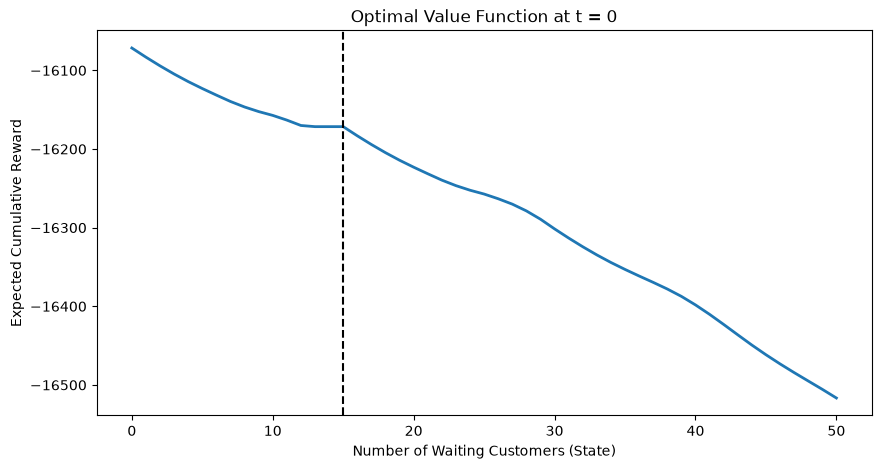

In [52]:
values = enumeration_solver.V[0]
states = range(len(values))
capacity = 15

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(states, values, linewidth=2, label="Optimal value function")
ax.axvline(
    x=capacity,
    linestyle="--",
    linewidth=1.5,
    label=f"Shuttle capacity ({capacity})",
    color="black",
)

ax.set(
    title="Optimal Value Function at t = 0",
    xlabel="Number of Waiting Customers (State)",
    ylabel="Expected Cumulative Reward",
)

plt.show()

# Checks

### Random Trajectory

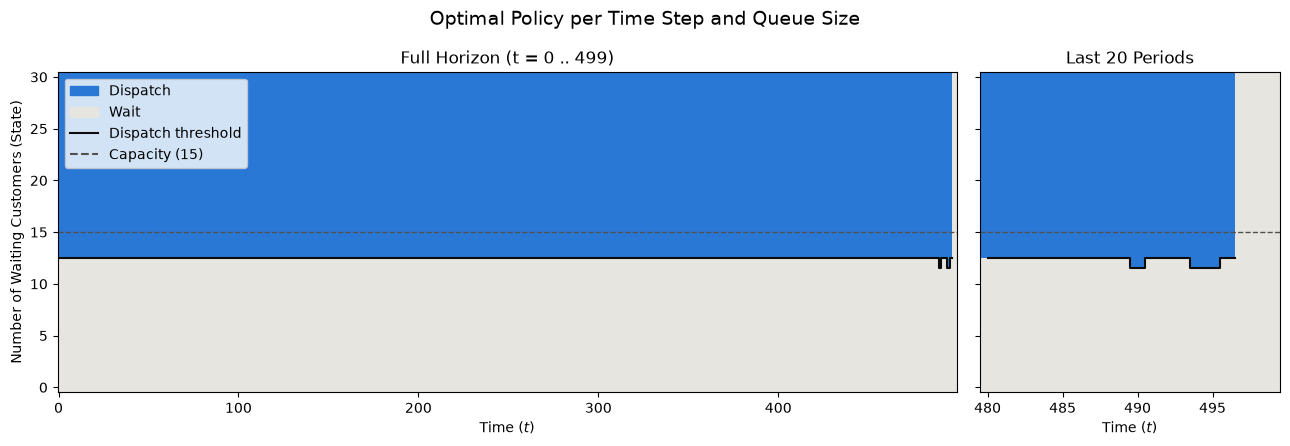

Dispatch threshold over time:
  t =   0 .. 489: dispatch if s >= 13
  t = 490 .. 490: dispatch if s >= 12
  t = 491 .. 493: dispatch if s >= 13
  t = 494 .. 495: dispatch if s >= 12
  t = 496 .. 496: dispatch if s >= 13
  t = 497 .. 499: never dispatch


In [55]:
from itertools import groupby

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

max_state_shown = 30  # Threshold sits well below this; higher states always dispatch
end_window = 20  # Number of final periods shown in the zoomed panel

# Optimal action for every (t, s): 1 = DISPATCH, 0 = WAIT
policy_states = np.arange(max_state_shown + 1)
policy = np.array(
    [
        [
            enumeration_solver.get_action(int(s), t)
            == ShuttleEnvironmentAction.DISPATCH
            for t in range(T)
        ]
        for s in policy_states
    ],
    dtype=int,
)

# Smallest queue size at which dispatching is optimal (NaN if never)
threshold = np.array(
    [policy_states[col.argmax()] if col.any() else np.nan for col in policy.T]
)

fig, (ax_full, ax_end) = plt.subplots(
    1, 2, figsize=(13, 4.5), sharey=True, width_ratios=(3, 1)
)

for ax, (t_from, t_to), title in (
    (ax_full, (0, T), f"Full Horizon (t = 0 .. {T - 1})"),
    (ax_end, (T - end_window, T), f"Last {end_window} Periods"),
):
    ax.imshow(
        policy[:, t_from:t_to],
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        cmap=ListedColormap(["#e6e5e0", "#2a78d6"]),
        vmin=0,
        vmax=1,
        extent=(t_from - 0.5, t_to - 0.5, -0.5, max_state_shown + 0.5),
    )
    ax.step(
        range(t_from, t_to),
        threshold[t_from:t_to]
        - 0.5,  # Draw on the lower edge of the first dispatch cell
        where="mid",
        color="#0b0b0b",
        linewidth=1.5,
    )
    ax.axhline(SHUTTLE_CAPACITY, linestyle="--", linewidth=1, color="#52514e")
    ax.set(title=title, xlabel="Time ($t$)")

ax_full.set_ylabel("Number of Waiting Customers (State)")
ax_full.legend(
    handles=[
        Patch(color="#2a78d6", label="Dispatch"),
        Patch(color="#e6e5e0", label="Wait"),
        plt.Line2D([], [], color="#0b0b0b", linewidth=1.5, label="Dispatch threshold"),
        plt.Line2D(
            [],
            [],
            linestyle="--",
            color="#52514e",
            label=f"Capacity ({SHUTTLE_CAPACITY})",
        ),
    ],
    loc="upper left",
)
fig.suptitle("Optimal Policy per Time Step and Queue Size", fontsize=14)
fig.tight_layout()
plt.show()

print("Dispatch threshold over time:")
t = 0
for value, run in groupby(threshold, key=lambda x: "never" if np.isnan(x) else int(x)):
    length = len(list(run))
    rule = "never dispatch" if value == "never" else f"dispatch if s >= {value}"
    print(f"  t = {t:>3} .. {t + length - 1:>3}: {rule}")
    t += length

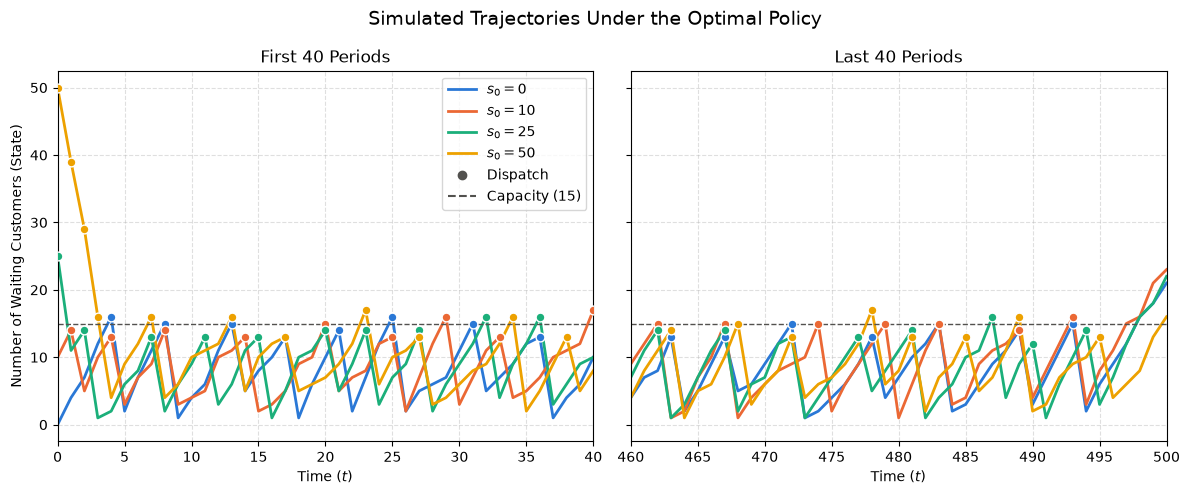

In [36]:
rng = np.random.default_rng(seed=42)
sample_initial_states = [0, 10, 25, 50]
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
window = 40  # Number of time steps shown at the start / end of the horizon

trajectories, dispatch_times = {}, {}

for s_0 in sample_initial_states:
    state = s_0
    trajectory, dispatches = [state], []

    for t in range(T):
        action = enumeration_solver.get_action(state, t)
        if action == ShuttleEnvironmentAction.DISPATCH:
            dispatches.append(t)

        # transitions returns (probability, next_state, reward) tuples
        probs, next_states, _ = zip(*shuttle_env.transitions(state, action))
        state = int(rng.choice(next_states, p=probs))

        trajectory.append(state)

    trajectories[s_0] = np.array(trajectory)
    dispatch_times[s_0] = np.array(dispatches, dtype=int)

fig, (ax_start, ax_end) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, (t_from, t_to), title in (
    (ax_start, (0, window), f"First {window} Periods"),
    (ax_end, (T - window, T), f"Last {window} Periods"),
):
    for s_0, color in zip(sample_initial_states, colors):
        ts = np.arange(t_from, t_to + 1)
        traj = trajectories[s_0]
        ax.plot(ts, traj[ts], color=color, linewidth=2, label=f"$s_0 = {s_0}$")

        d = dispatch_times[s_0]
        d = d[(d >= t_from) & (d <= t_to)]
        ax.scatter(d, traj[d], color=color, s=40, zorder=3, edgecolor="white")

    ax.axhline(SHUTTLE_CAPACITY, linestyle="--", linewidth=1, color="#52514e")
    ax.set(title=title, xlabel="Time ($t$)", xlim=(t_from, t_to))
    ax.grid(True, linestyle="--", alpha=0.4)

ax_start.set_ylabel("Number of Waiting Customers (State)")
ax_start.legend(
    handles=ax_start.get_legend_handles_labels()[0]
    + [
        plt.Line2D([], [], marker="o", linestyle="", color="#52514e", label="Dispatch"),
        plt.Line2D(
            [],
            [],
            linestyle="--",
            color="#52514e",
            label=f"Capacity ({SHUTTLE_CAPACITY})",
        ),
    ],
    loc="upper right",
)
fig.suptitle("Simulated Trajectories Under the Optimal Policy", fontsize=14)
fig.tight_layout()
plt.show()

### Random Policy

In [37]:
START_STATE = 0  # s_0 of the experiment
START_TIME = 0  # t_0 of the experiment
N_TRAJECTORIES = 50
RANDOM_DISPATCH_PROB = 0.5  # Random policy dispatches with this probability each period

rng = np.random.default_rng(seed=7)


def optimal_policy(state: int, t: int) -> ShuttleEnvironmentAction:
    return enumeration_solver.get_action(state, t)


def random_policy(state: int, t: int) -> ShuttleEnvironmentAction:
    if rng.random() < RANDOM_DISPATCH_PROB:
        return ShuttleEnvironmentAction.DISPATCH
    return ShuttleEnvironmentAction.WAIT


def rollout(policy, s_0: int, t_0: int) -> np.ndarray:
    """Simulate one trajectory from (t_0, s_0) until T and return the cumulative reward per step."""
    state, total = s_0, 0.0
    cumulative = [total]

    for t in range(t_0, T):
        outcomes = shuttle_env.transitions(state, policy(state, t))
        _, state, reward = outcomes[
            rng.choice(len(outcomes), p=[p for p, _, _ in outcomes])
        ]
        total += reward
        cumulative.append(total)

    return np.array(cumulative)


def evaluate_policy(dispatch_prob) -> list[np.ndarray]:
    """Exact expected reward-to-go V^pi[t][s] of a policy via backward recursion.

    dispatch_prob(t, states) returns the probability of dispatching in each state at time t.
    """
    arrivals = np.array(shuttle_env.customer_arriving_options)
    arrival_probs = np.array(shuttle_env.customer_arriving_probabilities)

    values = [np.zeros(len(enumeration_solver.V[T]))]

    for t in reversed(range(T)):
        states = np.arange(len(enumeration_solver.V[t]))
        q = {}

        for dispatch in (True, False):
            remaining = np.maximum(0, states - SHUTTLE_CAPACITY) if dispatch else states
            reward = -(
                remaining * CUSTOMER_WAITING_COST + dispatch * SHUTTLE_DISPATCH_COST
            )
            q[dispatch] = (
                reward + values[0][remaining[:, None] + arrivals] @ arrival_probs
            )

        p = dispatch_prob(t, states)
        values.insert(0, p * q[True] + (1 - p) * q[False])

    return values


# Value of the optimal policy (from the DP) and exact expected value of the random policy
v_optimal = enumeration_solver.get_value(START_STATE, START_TIME)
v_random = evaluate_policy(lambda t, s: np.full(len(s), RANDOM_DISPATCH_PROB))[
    START_TIME
][START_STATE]

# Exact expected value of every fixed threshold policy "dispatch if s >= k"
thresholds = np.arange(1, 41)
v_thresholds = np.array(
    [
        evaluate_policy(lambda t, s, k=k: (s >= k).astype(float))[START_TIME][
            START_STATE
        ]
        for k in thresholds
    ]
)

# Monte Carlo rollouts from (START_TIME, START_STATE)
optimal_returns = np.array(
    [rollout(optimal_policy, START_STATE, START_TIME) for _ in range(N_TRAJECTORIES)]
)
random_returns = np.array(
    [rollout(random_policy, START_STATE, START_TIME) for _ in range(N_TRAJECTORIES)]
)

best_k = thresholds[v_thresholds.argmax()]
print(f"V*(s={START_STATE}, t={START_TIME})                     = {v_optimal:>10.1f}")
print(
    f"Best fixed threshold (k = {best_k:>2})               = {v_thresholds.max():>10.1f}"
)
print(f"Random policy, exact expected value         = {v_random:>10.1f}")
print(
    f"Optimal rollouts, mean of {N_TRAJECTORIES}               = {optimal_returns[:, -1].mean():>10.1f}"
)
print(
    f"Random rollouts,  mean of {N_TRAJECTORIES}               = {random_returns[:, -1].mean():>10.1f}"
)
print(
    f"Random rollouts with return <= V*           = {(random_returns[:, -1] <= v_optimal).sum()} / {N_TRAJECTORIES}"
)

V*(s=0, t=0)                     =   -16071.6
Best fixed threshold (k = 13)               =   -16099.9
Random policy, exact expected value         =   -28299.9
Optimal rollouts, mean of 50               =   -16120.5
Random rollouts,  mean of 50               =   -28137.4
Random rollouts with return <= V*           = 50 / 50


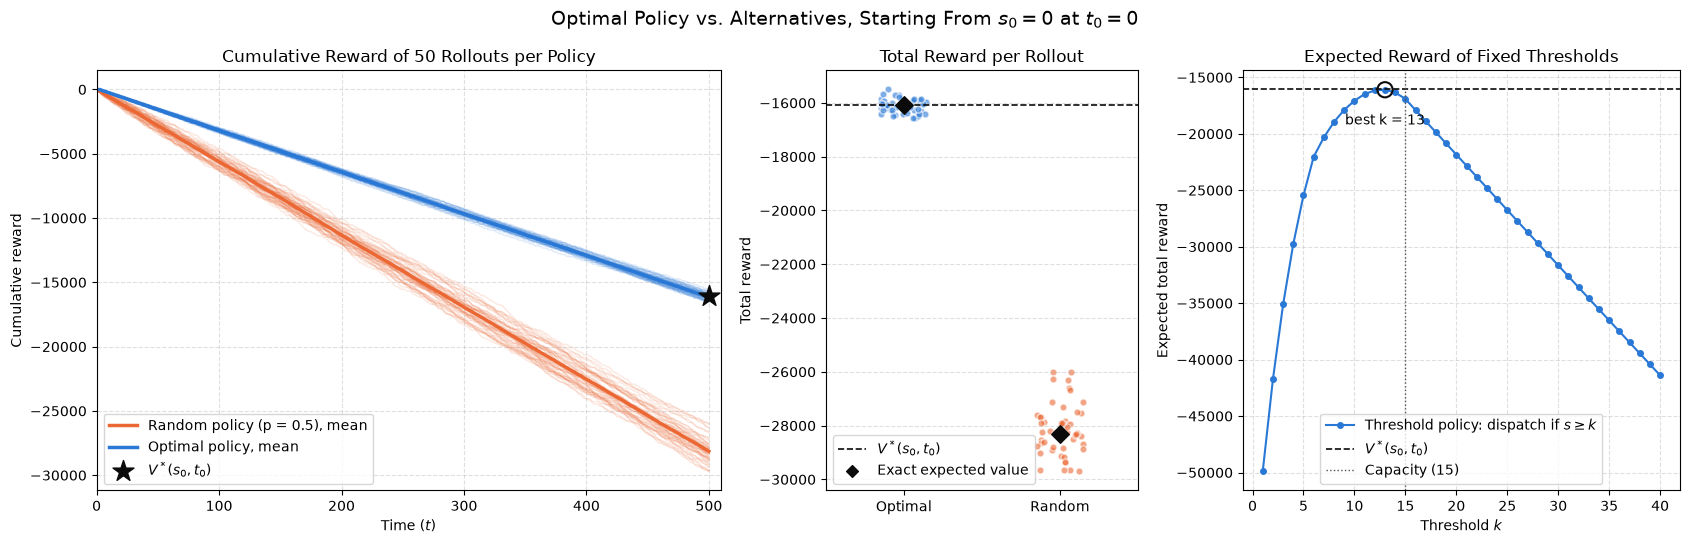

In [38]:
OPTIMAL_COLOR, RANDOM_COLOR, INK = "#2a78d6", "#eb6834", "#0b0b0b"

fig, (ax_paths, ax_returns, ax_thresholds) = plt.subplots(
    1, 3, figsize=(17, 5.5), width_ratios=(2, 1, 1.4)
)

# (a) Cumulative reward along each simulated trajectory
ts = np.arange(START_TIME, T + 1)
for returns, color, name in (
    (random_returns, RANDOM_COLOR, f"Random policy (p = {RANDOM_DISPATCH_PROB})"),
    (optimal_returns, OPTIMAL_COLOR, "Optimal policy"),
):
    for cumulative in returns:
        ax_paths.plot(ts, cumulative, color=color, alpha=0.15, linewidth=1)
    ax_paths.plot(
        ts, returns.mean(axis=0), color=color, linewidth=2.5, label=f"{name}, mean"
    )

ax_paths.scatter(
    T, v_optimal, marker="*", s=250, color=INK, zorder=3, label=r"$V^*(s_0, t_0)$"
)
ax_paths.set(
    title=f"Cumulative Reward of {N_TRAJECTORIES} Rollouts per Policy",
    xlabel="Time ($t$)",
    ylabel="Cumulative reward",
    xlim=(START_TIME, T + 10),
)
ax_paths.grid(True, linestyle="--", alpha=0.4)
ax_paths.legend(loc="lower left")

# (b) Final returns of every rollout vs. V*
for x, (returns, color, exact) in enumerate(
    (
        (optimal_returns, OPTIMAL_COLOR, v_optimal),
        (random_returns, RANDOM_COLOR, v_random),
    )
):
    jitter = rng.uniform(-0.15, 0.15, N_TRAJECTORIES)
    ax_returns.scatter(
        x + jitter, returns[:, -1], color=color, alpha=0.6, s=25, edgecolor="white"
    )
    ax_returns.scatter(x, exact, marker="D", s=80, color=INK, zorder=3)

ax_returns.axhline(
    v_optimal, linestyle="--", color=INK, linewidth=1.2, label=r"$V^*(s_0, t_0)$"
)
ax_returns.scatter([], [], marker="D", color=INK, label="Exact expected value")
ax_returns.set(
    title="Total Reward per Rollout",
    xticks=[0, 1],
    xticklabels=["Optimal", "Random"],
    xlim=(-0.5, 1.5),
    ylabel="Total reward",
)
ax_returns.grid(True, axis="y", linestyle="--", alpha=0.4)
ax_returns.legend(loc="lower left")

# (c) Exact expected value of every fixed threshold policy
ax_thresholds.plot(
    thresholds,
    v_thresholds,
    color=OPTIMAL_COLOR,
    marker="o",
    markersize=4,
    linewidth=1.5,
    label=r"Threshold policy: dispatch if $s \geq k$",
)
ax_thresholds.axhline(
    v_optimal, linestyle="--", color=INK, linewidth=1.2, label=r"$V^*(s_0, t_0)$"
)
ax_thresholds.scatter(
    best_k,
    v_thresholds.max(),
    s=120,
    facecolor="none",
    edgecolor=INK,
    linewidth=1.5,
    zorder=3,
)
ax_thresholds.annotate(
    f"best k = {best_k}",
    (best_k, v_thresholds.max()),
    xytext=(0, -25),
    textcoords="offset points",
    ha="center",
)
ax_thresholds.axvline(
    SHUTTLE_CAPACITY,
    linestyle=":",
    color="#52514e",
    linewidth=1,
    label=f"Capacity ({SHUTTLE_CAPACITY})",
)
ax_thresholds.set(
    title="Expected Reward of Fixed Thresholds",
    xlabel="Threshold $k$",
    ylabel="Expected total reward",
)
ax_thresholds.grid(True, linestyle="--", alpha=0.4)
ax_thresholds.legend(loc="lower center")

fig.suptitle(
    f"Optimal Policy vs. Alternatives, Starting From $s_0 = {START_STATE}$ at $t_0 = {START_TIME}$",
    fontsize=14,
)
fig.tight_layout()
plt.show()

## Correctness Checks
Each check states what I expect **before** looking at the output, then tests it with assertions (PASS / FAIL) and a plot:
1. **Remove the randomness:** with deterministic arrivals the DP must match a brute-force search over all action sequences.
2. **Extreme parameters:** settings where the optimal policy is obvious.
3. **Parameter sweeps:** the dispatch threshold must move in the intuitive direction.
4. **Structure of the value function:** monotonicity and a constant cost per period far from the horizon.
5. **First 10 steps:** how states, values, Q-values, actions and rewards interact at each step.

In [39]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

CHECK_T = 60  # Short horizon so that many problem variants can be re-solved quickly


def solve_variant(T: int = CHECK_T, **overrides) -> ShuttleEnumeration:
    """Solve the problem with some parameters changed (all others as in the main problem)."""
    params = {
        "shuttle_capacity": SHUTTLE_CAPACITY,
        "shuttle_dispatch_cost": SHUTTLE_DISPATCH_COST,
        "customer_waiting_cost": CUSTOMER_WAITING_COST,
        "customer_arriving_options": CUSTOMER_ARRIVING_OPTIONS,
        "customer_arriving_probabilities": CUSTOMER_ARRIVING_PROBABILITIES,
    } | overrides
    solver = ShuttleEnumeration(
        env=ShuttleEnvironment(**params),
        T=T,
        max_initial_customers_waiting=MAX_INITIAL_CUSTOMERS_WAITING,
    )
    solver.solve()
    return solver


def dispatch_threshold(solver: ShuttleEnumeration, t: int = 0) -> float:
    """Smallest state in which dispatching is optimal at time t (NaN if never)."""
    for s in range(MAX_INITIAL_CUSTOMERS_WAITING + 1):
        if solver.get_action(s, t) == ShuttleEnvironmentAction.DISPATCH:
            return s
    return np.nan


def is_threshold_policy(solver: ShuttleEnumeration, t: int = 0) -> bool:
    """True if the policy at time t waits below some state and dispatches from there on."""
    dispatch = [
        solver.get_action(s, t) == ShuttleEnvironmentAction.DISPATCH
        for s in range(MAX_INITIAL_CUSTOMERS_WAITING + 1)
    ]
    return all(a <= b for a, b in zip(dispatch, dispatch[1:]))


def q_values(solver: ShuttleEnumeration, state: int, t: int) -> dict:
    return {
        action: sum(
            p * (r + solver.V[t + 1][s_next])
            for p, s_next, r in solver.env.transitions(state, action)
        )
        for action in ShuttleEnvironmentAction
    }


def report(name: str, passed: bool) -> None:
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")

### Check 1: Deterministic Arrivals vs. Brute Force
If exactly 3 customers arrive every period, there is no randomness: the optimal value is simply the best total reward over all $2^T$ possible action sequences. For a short horizon ($T = 12$, i.e. 4,096 sequences) this can be enumerated directly. **Expected:** the DP value equals the brute-force optimum for every initial state.

[PASS] DP value equals brute force for s_0 = 0..30 (max |error| = 0.00e+00)


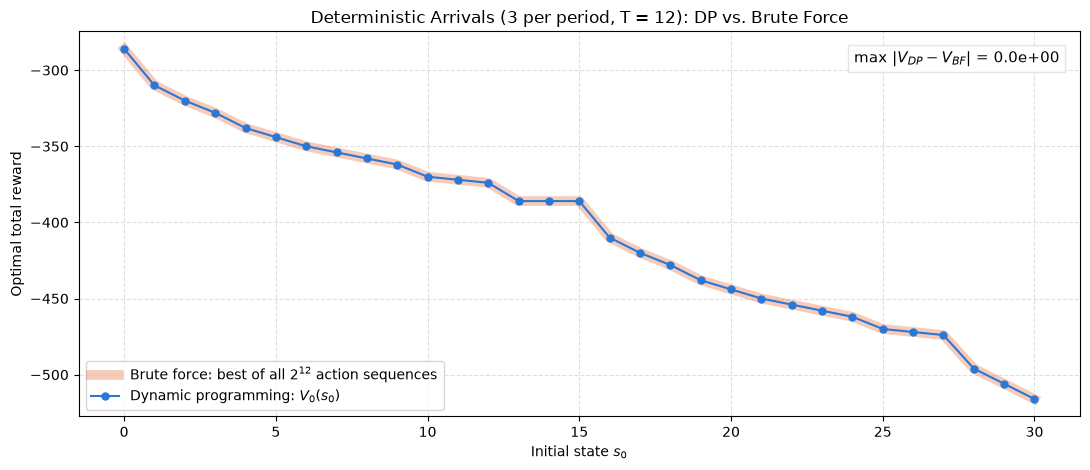

In [40]:
from itertools import product

BRUTE_FORCE_T = 12
DETERMINISTIC_ARRIVALS = 3

deterministic_solver = solve_variant(
    T=BRUTE_FORCE_T,
    customer_arriving_options=[DETERMINISTIC_ARRIVALS],
    customer_arriving_probabilities=[1.0],
)


def brute_force_value(s_0: int) -> float:
    """Best total reward over all 2^T action sequences (exact optimum without randomness)."""
    best = -np.inf
    for actions in product(ShuttleEnvironmentAction, repeat=BRUTE_FORCE_T):
        state, total = s_0, 0.0
        for action in actions:
            ((_, state, reward),) = deterministic_solver.env.transitions(state, action)
            total += reward
        best = max(best, total)
    return best


brute_force_states = np.arange(31)
v_dp = np.array([deterministic_solver.get_value(int(s), 0) for s in brute_force_states])
v_brute_force = np.array([brute_force_value(int(s)) for s in brute_force_states])
max_error = np.abs(v_dp - v_brute_force).max()

report(
    f"DP value equals brute force for s_0 = 0..{brute_force_states[-1]} (max |error| = {max_error:.2e})",
    np.allclose(v_dp, v_brute_force),
)

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(
    brute_force_states,
    v_brute_force,
    color="#eb6834",
    linewidth=7,
    alpha=0.35,
    label=f"Brute force: best of all $2^{{{BRUTE_FORCE_T}}}$ action sequences",
)
ax.plot(
    brute_force_states,
    v_dp,
    color="#2a78d6",
    marker="o",
    markersize=5,
    linewidth=1.5,
    label="Dynamic programming: $V_0(s_0)$",
)
ax.text(
    0.98,
    0.95,
    f"max $|V_{{DP}} - V_{{BF}}|$ = {max_error:.1e}",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=11,
    bbox=dict(facecolor="white", edgecolor="#e6e5e0"),
)
ax.set(
    title=f"Deterministic Arrivals ({DETERMINISTIC_ARRIVALS} per period, T = {BRUTE_FORCE_T}): DP vs. Brute Force",
    xlabel="Initial state $s_0$",
    ylabel="Optimal total reward",
)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

### Check 2: Extreme Parameters With Obvious Answers
| Setting | Expected optimal behaviour |
|---|---|
| $c_h = 0$ | Waiting is free, so never pay for a shuttle and $V \equiv 0$. |
| $c_f = 0$ | The shuttle is free, so dispatch whenever anyone is waiting. |
| $c_h = 200 > c_f = 100$ | One waiting customer already costs more than a shuttle, so dispatch whenever $s \geq 1$. |
| $K = 0$ | The shuttle carries nobody, so never dispatch. The queue grows by $\bar{a} = \mathbb{E}[A_t]$ per period, so $V_0(0) = -c_h \sum_{t=0}^{T-1} \bar{a}\,t = -c_h\,\bar{a}\,\frac{T(T-1)}{2}$. |

[PASS] No waiting cost: never dispatch, $V \equiv 0$
[PASS] Free shuttle: dispatch whenever $s \geq 1$
[PASS] Waiting > shuttle: dispatch whenever $s \geq 1$
[PASS] Useless shuttle: never dispatch, $V_0(0) = -c_h \bar{a} \frac{T(T-1)}{2}$


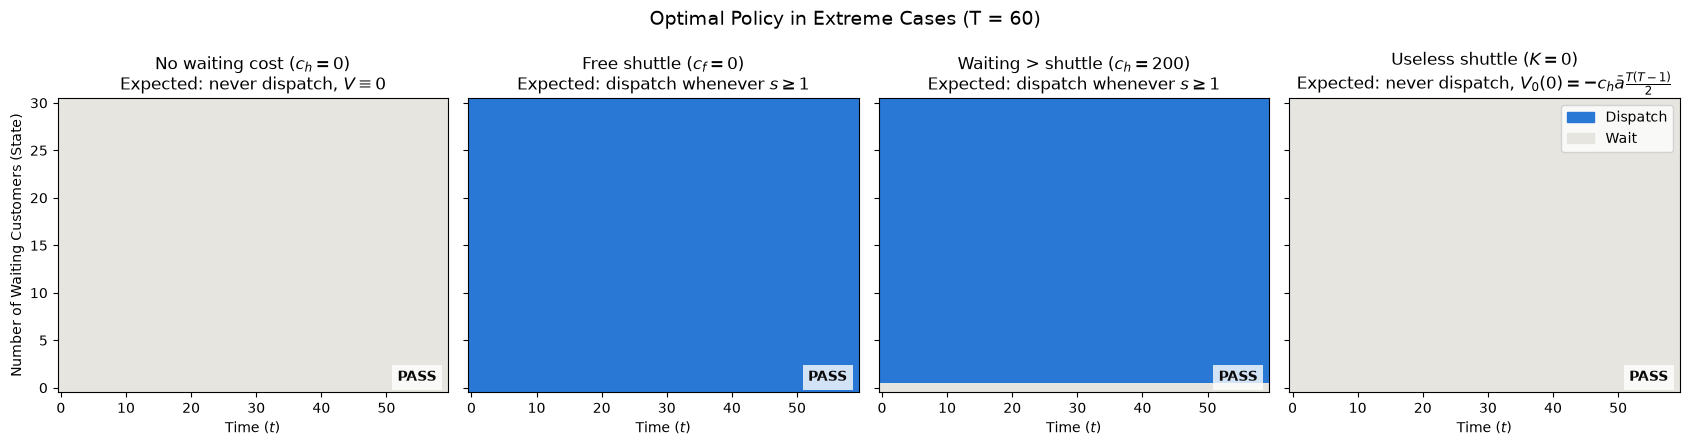

In [41]:
mean_arrivals = np.dot(CUSTOMER_ARRIVING_OPTIONS, CUSTOMER_ARRIVING_PROBABILITIES)
max_state_shown = 30

extreme_cases = [
    # (title, parameter overrides, expectation, check(policy_map, solver))
    (
        "No waiting cost ($c_h = 0$)",
        dict(customer_waiting_cost=0),
        "never dispatch, $V \\equiv 0$",
        lambda policy_map, solver: (
            policy_map.sum() == 0 and np.allclose(solver.V[0], 0)
        ),
    ),
    (
        "Free shuttle ($c_f = 0$)",
        dict(shuttle_dispatch_cost=0),
        "dispatch whenever $s \\geq 1$",
        lambda policy_map, solver: policy_map[1:].all(),
    ),
    (
        "Waiting > shuttle ($c_h = 200$)",
        dict(customer_waiting_cost=200),
        "dispatch whenever $s \\geq 1$",
        lambda policy_map, solver: policy_map[1:].all(),
    ),
    (
        "Useless shuttle ($K = 0$)",
        dict(shuttle_capacity=0),
        "never dispatch, $V_0(0) = -c_h \\bar{a} \\frac{T(T-1)}{2}$",
        lambda policy_map, solver: (
            policy_map.sum() == 0
            and np.isclose(
                solver.get_value(0, 0),
                -CUSTOMER_WAITING_COST * mean_arrivals * CHECK_T * (CHECK_T - 1) / 2,
            )
        ),
    ),
]

fig, axes = plt.subplots(1, len(extreme_cases), figsize=(17, 4.5), sharey=True)

for ax, (title, overrides, expected, check) in zip(axes, extreme_cases):
    solver = solve_variant(**overrides)
    policy_map = np.array(
        [
            [
                solver.get_action(s, t) == ShuttleEnvironmentAction.DISPATCH
                for t in range(CHECK_T)
            ]
            for s in range(max_state_shown + 1)
        ],
        dtype=int,
    )
    passed = bool(check(policy_map, solver))
    report(f"{title.split(' (')[0]}: {expected}", passed)

    ax.imshow(
        policy_map,
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        cmap=ListedColormap(["#e6e5e0", "#2a78d6"]),
        vmin=0,
        vmax=1,
        extent=(-0.5, CHECK_T - 0.5, -0.5, max_state_shown + 0.5),
    )
    ax.set(title=f"{title}\nExpected: {expected}", xlabel="Time ($t$)")
    ax.text(
        0.97,
        0.04,
        "PASS" if passed else "FAIL",
        transform=ax.transAxes,
        ha="right",
        fontweight="bold",
        color="#0b0b0b",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.8),
    )

axes[0].set_ylabel("Number of Waiting Customers (State)")
axes[-1].legend(
    handles=[
        Patch(color="#2a78d6", label="Dispatch"),
        Patch(color="#e6e5e0", label="Wait"),
    ],
    loc="upper right",
)
fig.suptitle(f"Optimal Policy in Extreme Cases (T = {CHECK_T})", fontsize=14)
fig.tight_layout()
plt.show()

### Check 3: Parameter Sweeps
Change one parameter at a time and track the dispatch threshold (smallest queue at which the policy dispatches at $t = 0$). Expected direction:
- **Dispatch cost $c_f$ ↑ ⇒ threshold ↑:** a dispatch is more expensive, so it is worth collecting more customers first.
- **Waiting cost $c_h$ ↑ ⇒ threshold ↓:** customers become expensive to keep, so dispatch earlier.
- **Capacity $K$ ↑ ⇒ threshold ↑ (then flattens):** a small shuttle forces dispatching once it is full; a large one stops being the bottleneck, so the threshold is then set by the $c_f$ / $c_h$ trade-off alone.

The policy should also stay threshold-shaped (wait below some $s$, dispatch above) for every parameter value.

[PASS] Threshold is increasing in the dispatch cost: [0, 4, 7, 11, 12, 13, 13, 14, 14, 15]
[PASS] Policy is threshold-shaped for every dispatch cost
[PASS] Threshold is decreasing in the waiting cost: [15, 15, 14, 13, 11, 7, 5, 3, 2, 1]
[PASS] Policy is threshold-shaped for every waiting cost
[PASS] Threshold is increasing in the capacity: [1, 2, 5, 9, 13, 16, 16, 16, 16, 16]
[PASS] Policy is threshold-shaped for every capacity


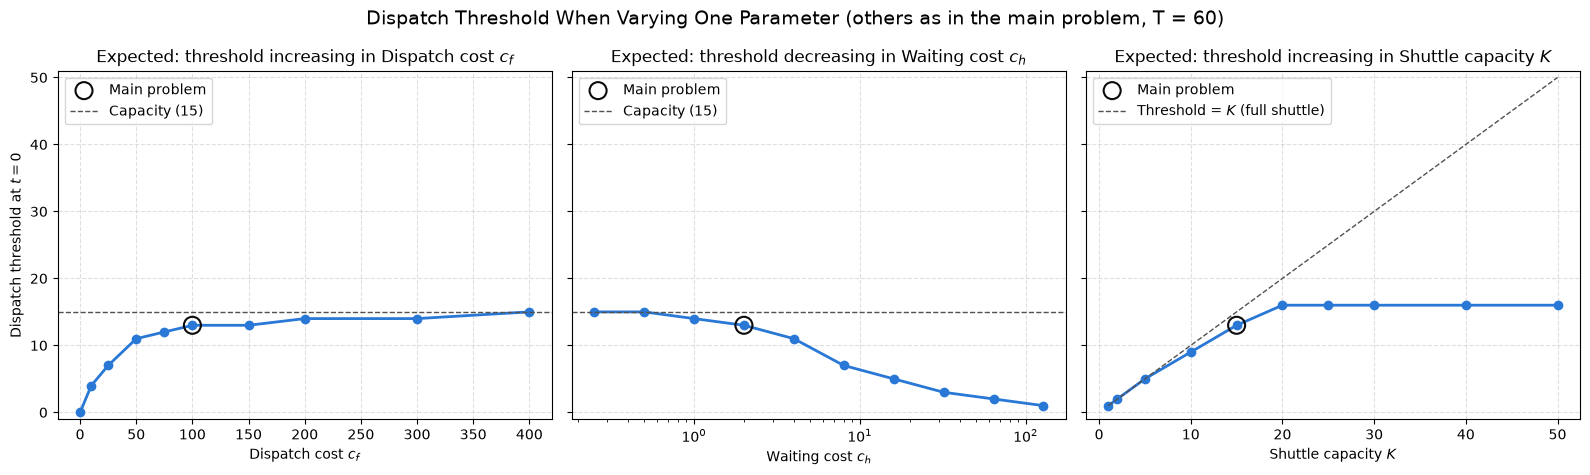

In [42]:
sweeps = [
    # (parameter, axis label, plain name, values, expected direction, log x-axis)
    (
        "shuttle_dispatch_cost",
        "Dispatch cost $c_f$",
        "dispatch cost",
        [0, 10, 25, 50, 75, 100, 150, 200, 300, 400],
        "increasing",
        False,
    ),
    (
        "customer_waiting_cost",
        "Waiting cost $c_h$",
        "waiting cost",
        [0.25, 0.5, 1, 2, 4, 8, 16, 32, 64, 128],
        "decreasing",
        True,
    ),
    (
        "shuttle_capacity",
        "Shuttle capacity $K$",
        "capacity",
        [1, 2, 5, 10, 15, 20, 25, 30, 40, 50],
        "increasing",
        False,
    ),
]
defaults = {
    "shuttle_dispatch_cost": SHUTTLE_DISPATCH_COST,
    "customer_waiting_cost": CUSTOMER_WAITING_COST,
    "shuttle_capacity": SHUTTLE_CAPACITY,
}

fig, axes = plt.subplots(1, len(sweeps), figsize=(16, 4.8), sharey=True)

for ax, (param, label, name, sweep_values, direction, log_x) in zip(axes, sweeps):
    solvers = [solve_variant(**{param: v}) for v in sweep_values]
    thresholds_ = np.array([dispatch_threshold(s) for s in solvers])

    steps = np.diff(thresholds_[~np.isnan(thresholds_)])
    monotone = np.all(steps >= 0) if direction == "increasing" else np.all(steps <= 0)
    report(f"Threshold is {direction} in the {name}: {thresholds_.tolist()}", monotone)
    report(
        f"Policy is threshold-shaped for every {name}",
        all(map(is_threshold_policy, solvers)),
    )

    ax.plot(sweep_values, thresholds_, color="#2a78d6", marker="o", linewidth=2)
    default_idx = sweep_values.index(defaults[param])
    ax.scatter(
        defaults[param],
        thresholds_[default_idx],
        s=150,
        facecolor="none",
        edgecolor="#0b0b0b",
        linewidth=1.5,
        zorder=3,
        label="Main problem",
    )

    if param == "shuttle_capacity":
        ax.plot(
            sweep_values,
            sweep_values,
            linestyle="--",
            color="#52514e",
            linewidth=1,
            label="Threshold = $K$ (full shuttle)",
        )
    else:
        ax.axhline(
            SHUTTLE_CAPACITY,
            linestyle="--",
            color="#52514e",
            linewidth=1,
            label=f"Capacity ({SHUTTLE_CAPACITY})",
        )

    ax.set(
        title=f"Expected: threshold {direction} in {label}",
        xlabel=label,
        xscale="log" if log_x else "linear",
        ylim=(-1, MAX_INITIAL_CUSTOMERS_WAITING + 1),
    )
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(loc="upper left")

axes[0].set_ylabel("Dispatch threshold at $t = 0$")
fig.suptitle(
    f"Dispatch Threshold When Varying One Parameter (others as in the main problem, T = {CHECK_T})",
    fontsize=14,
)
fig.tight_layout()
plt.show()

### Check 4: Trace the First 10 Steps
Follow one simulated trajectory step by step and check how state, value, Q-values, action and reward fit together:
- $V_t(s_t) = \max_a Q_t(s_t, a)$ at every step (Bellman equation).
- The policy dispatches exactly when $Q_t(s_t, \text{DISPATCH}) \geq Q_t(s_t, \text{WAIT})$, i.e. when the queue reaches the threshold.
- The reward is $-(c_h \cdot \text{customers left behind} + c_f \cdot \mathbb{1}[\text{dispatch}])$.

 t  s_t   V_t(s_t)  Q(DISPATCH)    Q(WAIT)    action  left  reward  arrive  s_t+1
 0    0   -16071.6     -16171.6   -16071.6      WAIT     0       0       3      3
 1    3   -16072.3     -16139.2   -16072.3      WAIT     3      -6       5      8
 2    8   -16081.9     -16106.9   -16081.9      WAIT     8     -16       1      9
 3    9   -16055.4     -16074.5   -16055.4      WAIT     9     -18       5     14
 4   14   -16042.2     -16042.2   -16059.9  DISPATCH     0    -100       2      2
 5    2   -15932.6     -16009.8   -15932.6      WAIT     2      -4       3      5
 6    5   -15929.0     -15977.5   -15929.0      WAIT     5     -10       5     10
 7   10   -15930.9     -15945.2   -15930.9      WAIT    10     -20       3     13
 8   13   -15912.8     -15912.8   -15920.0  DISPATCH     0    -100       3      3
 9    3   -15813.6     -15880.5   -15813.6      WAIT     3      -6       1      4

[PASS] V_t(s_t) = max_a Q_t(s_t, a) at every step (Bellman equation)
[PASS] Chosen action is the 

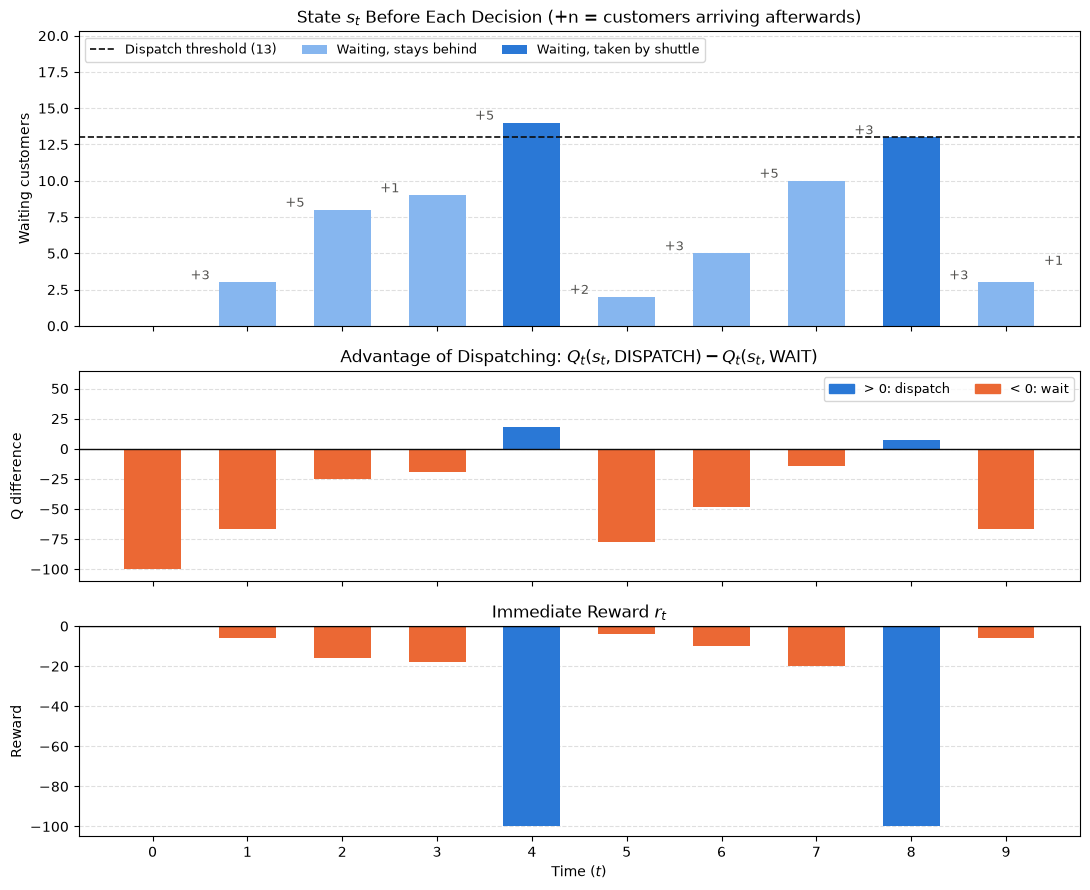

In [44]:
TRACE_STEPS = 10
TRACE_START_STATE = 0

trace_rng = np.random.default_rng(seed=1)
state = TRACE_START_STATE
rows = []

for t in range(TRACE_STEPS):
    q = q_values(enumeration_solver, state, t)
    action = enumeration_solver.get_action(state, t)
    dispatch = action == ShuttleEnvironmentAction.DISPATCH

    outcomes = shuttle_env.transitions(state, action)
    _, next_state, reward = outcomes[
        trace_rng.choice(len(outcomes), p=[p for p, _, _ in outcomes])
    ]
    remaining = max(0, state - SHUTTLE_CAPACITY) if dispatch else state

    rows.append(
        dict(
            t=t,
            s=state,
            V=enumeration_solver.get_value(state, t),
            q_dispatch=q[ShuttleEnvironmentAction.DISPATCH],
            q_wait=q[ShuttleEnvironmentAction.WAIT],
            action=action,
            remaining=remaining,
            reward=reward,
            arrivals=next_state - remaining,
            next_state=next_state,
        )
    )
    state = next_state

print(
    f"{'t':>2} {'s_t':>4} {'V_t(s_t)':>10} {'Q(DISPATCH)':>12} {'Q(WAIT)':>10} "
    f"{'action':>9} {'left':>5} {'reward':>7} {'arrive':>7} {'s_t+1':>6}"
)
for r in rows:
    print(
        f"{r['t']:>2} {r['s']:>4} {r['V']:>10.1f} {r['q_dispatch']:>12.1f} {r['q_wait']:>10.1f} "
        f"{r['action'].name:>9} {r['remaining']:>5} {r['reward']:>7.0f} {r['arrivals']:>7} {r['next_state']:>6}"
    )
print()

report(
    "V_t(s_t) = max_a Q_t(s_t, a) at every step (Bellman equation)",
    all(np.isclose(r["V"], max(r["q_dispatch"], r["q_wait"])) for r in rows),
)
report(
    "Chosen action is the one with the larger Q-value",
    all(
        (r["action"] == ShuttleEnvironmentAction.DISPATCH)
        == (r["q_dispatch"] >= r["q_wait"])
        for r in rows
    ),
)
report(
    "Reward = -(c_h * customers left behind + c_f * dispatch)",
    all(
        r["reward"]
        == -(
            CUSTOMER_WAITING_COST * r["remaining"]
            + SHUTTLE_DISPATCH_COST * (r["action"] == ShuttleEnvironmentAction.DISPATCH)
        )
        for r in rows
    ),
)
report(
    "Arrivals are always one of the allowed options",
    all(r["arrivals"] in CUSTOMER_ARRIVING_OPTIONS for r in rows),
)

ts = np.array([r["t"] for r in rows])
dispatched = np.array([r["action"] == ShuttleEnvironmentAction.DISPATCH for r in rows])
advantage = np.array([r["q_dispatch"] - r["q_wait"] for r in rows])

fig, (ax_state, ax_adv, ax_reward) = plt.subplots(
    3, 1, figsize=(11, 9), sharex=True, height_ratios=(1.4, 1, 1)
)

# State before the decision, split into customers served and customers left behind
served = np.array([r["s"] - r["remaining"] for r in rows])
left = np.array([r["remaining"] for r in rows])
ax_state.bar(ts, left, width=0.6, color="#86b6ef", label="Waiting, stays behind")
ax_state.bar(
    ts,
    served,
    bottom=left,
    width=0.6,
    color="#2a78d6",
    label="Waiting, taken by shuttle",
)
ax_state.axhline(
    threshold[0],
    linestyle="--",
    color="#0b0b0b",
    linewidth=1.2,
    label=f"Dispatch threshold ({int(threshold[0])})",
)
for r in rows:
    ax_state.annotate(
        f"+{r['arrivals']}",
        (r["t"] + 0.5, r["next_state"]),
        ha="center",
        va="bottom",
        color="#52514e",
        fontsize=9,
    )
ax_state.set(
    title="State $s_t$ Before Each Decision (+n = customers arriving afterwards)",
    ylabel="Waiting customers",
)
ax_state.set_ylim(0, max(r["s"] for r in rows) * 1.45)
ax_state.legend(loc="upper left", fontsize=9, ncol=3)

# Advantage of dispatching: positive means DISPATCH is optimal
ax_adv.bar(
    ts, advantage, width=0.6, color=np.where(advantage >= 0, "#2a78d6", "#eb6834")
)
ax_adv.axhline(0, color="#0b0b0b", linewidth=1)
ax_adv.set(
    title=r"Advantage of Dispatching: $Q_t(s_t, \mathrm{DISPATCH}) - Q_t(s_t, \mathrm{WAIT})$",
    ylabel="Q difference",
)
ax_adv.legend(
    handles=[
        Patch(color="#2a78d6", label="> 0: dispatch"),
        Patch(color="#eb6834", label="< 0: wait"),
    ],
    loc="upper right",
    fontsize=9,
    ncol=2,
)
ax_adv.set_ylim(
    advantage.min() * 1.1, max(advantage.max(), 0) + 0.4 * np.ptp(advantage)
)

# Immediate reward per step
ax_reward.bar(
    ts,
    [r["reward"] for r in rows],
    width=0.6,
    color=np.where(dispatched, "#2a78d6", "#eb6834"),
)
ax_reward.axhline(0, color="#0b0b0b", linewidth=1)
ax_reward.set(
    title="Immediate Reward $r_t$", xlabel="Time ($t$)", ylabel="Reward", xticks=ts
)

for ax in (ax_state, ax_adv, ax_reward):
    ax.grid(True, axis="y", linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)

fig.tight_layout()
plt.show()